In [1]:
import scipy.stats as st
import numpy as np
error_tipo_1 = (st.norm.cdf(496,loc=500,scale=np.sqrt(50)))**2
print(error_tipo_1)

error_tipo_2 =  1-(st.norm.cdf(496,loc=490,scale=np.sqrt(50)))**2
print(error_tipo_2)

0.0816838249422735
0.35691140996250237


In [2]:
g = st.norm.ppf(error_tipo_1, loc=1000, scale=np.sqrt(100))
g

np.float64(986.0616570701271)

In [3]:
error_tipo_2_opt = 1-(st.norm.cdf(g,loc=980,scale=np.sqrt(100)))
error_tipo_2_opt

np.float64(0.2722023611329887)

In [4]:
g = st.norm.ppf(0.05, loc=1000, scale=np.sqrt(100))
g

error_tipo_2_opt = 1-(st.norm.cdf(g,loc=980,scale=np.sqrt(100)))
error_tipo_2_opt

np.float64(0.36123996868766617)

In [5]:
import scipy.stats as st
import numpy as np
alpha = 0.05

g_1 = st.norm.ppf(alpha/2, loc=0, scale=np.sqrt(25))
g_1

g_2 = st.norm.ppf(1- alpha/2, loc=0, scale=np.sqrt(25))
g_2

print(g_1, g_2)

-9.799819922700273 9.79981992270027


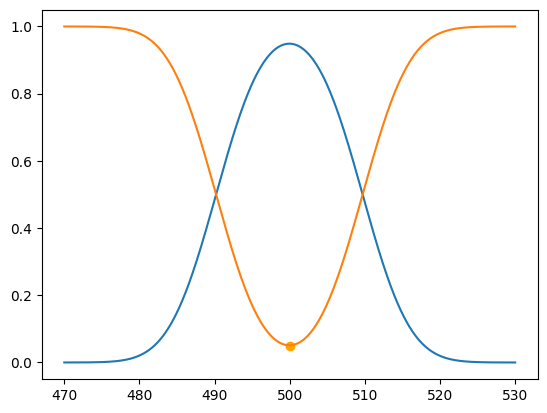

In [6]:
import matplotlib.pyplot as plt

alpha = 0.05
mu = np.linspace(470, 530, 1000)
mu0 = 500
b = 509.70
a = 490.20
error_st = 5
beta = st.norm.cdf((b-mu)/error_st, loc=0, scale=1) - st.norm.cdf((a-mu)/error_st, loc=0, scale=1)

pi = 1- beta # potencia

plt.plot(mu, beta)
plt.plot(mu, pi)
plt.scatter(mu0, alpha, color='orange')

In [ ]:
alpha = 0.05
n = 36
media_muestral = 17
varianza_muestral = 9
mu0 = 15

t_alpha = st.t.ppf(1-alpha, n-1)

T = (media_muestral-mu0)/(np.sqrt(varianza_muestral)/np.sqrt(n))

if T > t_alpha:
    print('Se rechaza H_0')
else:
    print('Se acepta H_0')

4.0
Se rechaza H_0


In [ ]:
import seaborn as sns

# hipotesis nula: mu_primera >= mu_total
# hipotesis aleternativa mu_primera < mu_total, prueba de cola izquierda

titanic = sns.load_dataset('titanic')
titanic

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


In [15]:
titanic.isna().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [21]:
# hipotesis nula: mu_primera >= mu_total
# hipotesis aleternativa mu_primera < mu_total, prueba de cola izquierda

primera_clase = titanic[titanic['pclass']==1]

mu_total = titanic['age'].mean()
mu_primera = primera_clase['age'].mean()

print(mu_total, mu_primera)
print('\n')

std_total = titanic['age'].std(ddof=0)
std_primera = primera_clase['age'].std(ddof=1)

#print(std_total, std_primera)

#porque existe NaN
n_total = titanic['age'].count()
n_primera = primera_clase['age'].count()

#print(n_total, n_primera)


alpha = 0.05
z_alpha = st.norm.ppf(alpha, loc=0, scale=1)
z = (mu_primera - mu_total)/(std_total/np.sqrt(n_primera))
print(z_alpha, z)
if z < z_alpha:
    print('Se rechaza H_0, la media de la primera clase es menor a la media total')
else:
    print('Se acepta H_0, la media de la primera clase es mayor o igual a la media total')

print('\n')

t_alpha = st.t.ppf(alpha, n_primera-1)

T = (mu_primera - mu_total)/(std_primera/np.sqrt(n_primera))
print(t_alpha, T)
if T < t_alpha:
    print('Se rechaza H_0, la media de la primera clase es menor a la media total')
else:
    print('Se acepta H_0, la media de la primera clase es mayor o igual a la media total')


29.69911764705882 38.233440860215055


-1.6448536269514729 8.018054259930421
Se acepta H_0, la media de la primera clase es mayor o igual a la media total


-1.653131868631923 7.862851023885084
Se acepta H_0, la media de la primera clase es mayor o igual a la media total


In [22]:
# H_0: sigma^2 >= 64
# H_1: sigma^2 < 64

bills = sns.load_dataset('tips')
bills

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


In [ ]:
# H_0: sigma^2 >= 64
# H_1: sigma^2 < 64

varianza_muestral = bills['total_bill'].var(ddof=1)
print(varianza_muestral)
varianza_poblacional = 64
n = bills['total_bill'].count()

alpha = 0.05

chi2_alpha = st.chi2.ppf(alpha, n-1)
chi2 = ((n-1)*varianza_muestral)/varianza_poblacional


if chi2 < chi2_alpha:
    print('Se rechaza H_0, ')
else:
    print('Se acepta H_0, ')

79.25293861397827
Se acepta H_0, 
